# Orbits: preliminary task

## Imports

In the following cell, you should import whatever you need from the NumPy and Matplotlib libraries.

In [4]:
# STUDENT COMPLETED CELL
import numpy as np
import matplotlib.pyplot as plt

You will also need to download two additional Python files into the same folder as your notebook so that you can import the functions specified in the next cell:

- `phas0007anim_v2.py` contains updated versions of the animation helper functions that you used in unit 9;
- `assignment_tests` contains some functions that are used in this notebook to verify that your own functions work correctly.

In [5]:
from phas0007anim_v2 import animate_trajectory_2d, animate_trajectories_2d
from assignment_tests import test_force, test_move_planet, test_trajectory_return_type

The following cell defines some useful constants for use throughout the notebook.

In [6]:
G       = 6.6743e-11 # gravitational constant [m^3 kg^-1 s^-2]
YEAR    = 3.154e7    # one year in seconds
M_SOLAR = 1.989e30   # solar mass [kg]
AU      = 1.496e11   # one astronomical unit (mean orbital radius of Earth) [m]

## Calculating the gravitational force between two objects

You should complete the following function, without changing its name, arguments or docstring, to calculate the force on one object due to the gravitational field of another. **We will only be using two dimensions in this assignment**, but your function should also work for the three-dimensional case if you design it carefully and avoid breaking vectors down into their Cartesian components.

In [27]:
def force(pos1, pos2, m1, m2):
    """
    Calculate the gravitational force exerted by object 1 on object 2.
    
    Input:
        pos1: position vector of first object  (NumPy array)
        pos2: position vector of second object (NumPy array)
        m1:   mass of first object
        m2:   mass of second object

    Depends on:
        G  (global variable):    gravitational constant [m^3 kg^-1 s^-2]

    Return:
        force on object 2 [N] (NumPy array)
    """
    ##################
    # YOUR CODE HERE #
    ##################
    global G

    r=pos2-pos1
    r_mag=np.linalg.norm(r)

    force=-G*m1*m2*r/r_mag**3

    return force
    


#### Testing your function

The following cell applies some tests to help you make sure your `force` function works correctly before you use it in the rest of the task. To use these tests you will need to download the file `assignment_tests.py` and place it in the same folder as your notebook.

You do not need to understand the details of how it works, but it may help you narrow down any bugs in your code. If each line of output starts with `OK` then it is likely (but not guaranteed) that you have implemented the function correctly.

In [28]:
# Check that "force" gives correct results in selected cases
test_force(force)

OK: correct results for test 'distance = 1 in x direction'
OK: correct results for test 'swap objects'
OK: correct results for test 'distance = 2'
OK: correct results for test 'distance = 1 in y direction'
OK: correct results for test 'displaced from origin'
OK: correct results for test 'non-unit mass 1'
OK: correct results for test 'non-unit mass 2'


## Calculating the motion of a planet in the gravitational field of a star

You should complete the following function, without changing its name, arguments or docstring, to calculate the new position and velocity of a planet after a time step `dt`, in the gravitational field of a star of a given mass situated at the origin. This function will need to call `force` to calculate the acceleration vector of the planet.

In [29]:
def move_planet(position, velocity, m_star, dt):
    """
    Calculate motion of planet in the gravitational field of a star with given mass
    at the originin two dimensions, using Euler's method.
    
    Input:
      - position: position vector of planet at start of time step (NumPy array: x, y)
      - velocity: velocity vector of planet at start of time step (NumPy array: vx, vy)
      - m_star:   mass of star
      - dt:       time step
      
    Output: (position_new, velocity_new)
      - position_new: position vector of planet at end of time step (NumPy array: x, y)
      - velocity_new: velocity vector of planet at end of time step (NumPy array: vx, vy)
      
    Depends on:
      - force = function to calculate the gravitational force between two objects
    """
    ##################
    # YOUR CODE HERE #
    ##################

    star_pos=np.array([0.0,0.0])
    acc=force(star_pos,position,m_star,1)
    pos_new=position+velocity*dt
    vel_new=velocity+acc*dt

    return pos_new,vel_new

    


#### Testing your function

The following cell applies some tests to help you make sure your `move_planet` function works correctly before you use it in the rest of the task. To use these tests you will need to download the file `assignment_tests.py` and place it in the same folder as your notebook.

You do not need to understand the details of how it works, but it may help you narrow down any bugs in your code. If each line of output starts with `OK` then it is likely (but not guaranteed) that you have implemented the function correctly.

In [30]:
# Check that "move_planet" gives correct results in selected cases
test_move_planet(move_planet)

OK: correct results for test 'zero time-step'
OK: correct results for test 'planet starts at rest'
OK: correct results for test 'planet moving away from star'
OK: correct results for test 'planet moving towards star'
OK: correct results for test 'planet moving past star'
OK: correct results for test 'smaller time-step'
OK: correct results for test 'larger stellar mass'


## Calculating the orbit of a planet

You should complete the following function, without changing its name, arguments or docstring, to calculate the $x$ and $y$ coordinates of a planet at each time step.

In [31]:
def trajectory(position, velocity, m_star, dt, t_max):
    """
    Calculate trajectory of planet from given starting position in two dimensions, using Euler's method.
    
    Input:
      - position: position vector of planet at start of simulation [m] (NumPy array: x, y)
      - velocity: velocity vector of planet at start of simulation [m] (NumPy array: vx, vy)
      - m_star:   mass of star [kg]
      - dt:       time step    [s]
      - t_max:    duration of calculated motion [s]

    Returns:
        Trajectory as a 2 x N array containing x and y coordinates at each instant.
    """
    ##################
    # YOUR CODE HERE #
    ##################

    t=0
    x,y=position
    x_arr,y_arr=[x],[y]
    
    while t<=t_max:
        t+=dt
        position,velocity=move_planet(position, velocity, m_star, dt)
        x,y=position
        x_arr.append(x)
        y_arr.append(y)

    ans=np.array([x_arr,y_arr])

    return ans
        

    


#### Testing your function

For the animations later in the notebook, it is important to have each trajectory in the form of a 2D (2 x N) array containing the $x$ and $y$ coordinates in the two rows. The function used below does not test your trajectory function thoroughly, but checks whether it returns an object of incorrect type.

In [32]:
# Check function returns 2D array
test_trajectory_return_type(trajectory)

OK: function return array with dimensions 2 x N


Here we include the function you were given in unit 8 to simplify the plotting of trajectories.

In [13]:
def plot_trajectory(x, y, label="trajectory", fmt='-'):
    """Plot trajectory with equal aspect ratio, using existing figure.

    Arguments:
        x, y:  arrays of x- and y-coordinates
        label: (optional) label for use in legend
        fmt:   (optional) format to use for plotting, e.g. ':' for dotted line
    """
    plt.plot(x,y,fmt,label=label)
    plt.gca().set_aspect('equal') # same scale horizontally and vertically
    plt.xlabel('x [m]')
    plt.ylabel('y [m]')

If you have implemented all three functions correctly, the following cell should show an almost circular orbit.

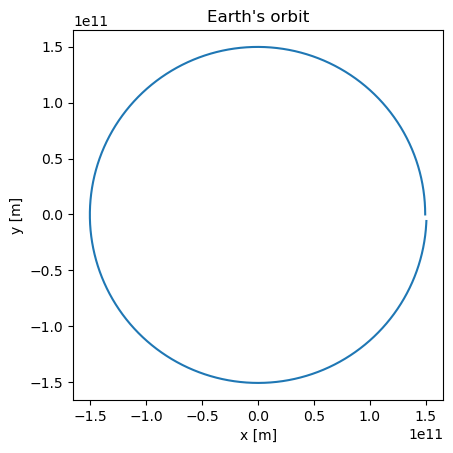

In [14]:
# Calculate orbital speed of Earth [m/s] assuming circular orbit
v_earth = np.sqrt(G*M_SOLAR/AU)

# Initial conditions of planet
pos_earth = np.array([AU, 0])       # position (x,y) [m]
vel_earth = np.array([0,v_earth])   # velocity (vx,vy) [m/s]

# Calculate trajectory
dt = YEAR/10000                # time step for Euler's method [s]
traj_earth = trajectory(pos_earth,vel_earth,M_SOLAR,dt,1*YEAR)

# Plot trajectory
plt.figure()
plt.title("Earth's orbit")
x_earth, y_earth = traj_earth
plot_trajectory(x_earth, y_earth)

## Animating the orbit

In the cell below, write some code that calls the appropriate function from to create an animation of the orbit you have calculated above. You should choose parameters to create a fairly smooth animation that takes a few seconds to run. The animation functions in the updated version of `phas0007anim_v2` have optional arguments that allow you to set the title and axis labels.

In [15]:
# STUDENT COMPLETED CELL


animate_trajectory_2d(traj_earth,20,5)

## Two non-interacting planets

If all your functions are correct, the following cell should create a plot showing the orbits of Earth and Venus.

<Figure size 640x480 with 0 Axes>

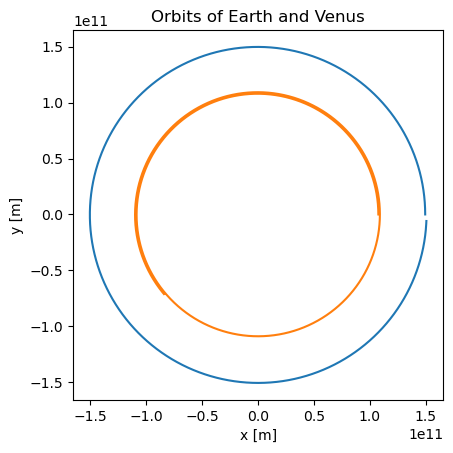

In [16]:
# Orbital parameters of Venus
r_venus = 0.72 * AU
v_venus = np.sqrt(G*M_SOLAR/r_venus)
pos_venus = np.array([r_venus,0])     # initial position (x,y) [m]
vel_venus = np.array([0, v_venus])    # initial velocity (vx,vy) [m/s]

# Calculate trajectory
traj_venus = trajectory(pos_venus,vel_venus,M_SOLAR,dt,1*YEAR)
x_venus, y_venus = traj_venus

# Plot trajectories
plt.figure()
plt.title('Orbits of Earth and Venus')
plot_trajectory(x_earth, y_earth)
plot_trajectory(x_venus, y_venus)

## Animating two orbits

In the cell below, write some code that calls the appropriate function to create an animation of the two orbits calculated above. You should choose parameters to create a fairly smooth animation that takes a few seconds to run.

In [33]:
# STUDENT COMPLETED CELL
trajectories=[traj_earth]
trajectories.append(traj_venus)
animate_trajectories_2d(trajectories,20,5)
